# Detección de anomalías en logs de HDFS con aprendizaje automático clásico
## Etapa 2: Modelado, explicabilidad y evaluación
### Track A (ML tabular)

#### Instituto Tecnológico de Costa Rica
#### Inteligencia Artificial
#### Profesor: Kenneth Obando Rodríguez
#### Integrantes: Luis Fernando Ureña Corrales - 2023064329, Fabricio Herrera Rodríguez - 2023097390
#### Dataset: HDFS_v1 (Loghub)

## 1. Configuración y carga de datos


Configuración de datos

In [ ]:
!pip install -q shap

import os
import numpy as np, pandas as pd

SEED = 42
np.random.seed(SEED)

EVENT_COLS = [f"E{i}" for i in range(1, 30)]

BASELINE_LITERATURA_F1 = 0.9410

DATA_DIR = "/content" if os.path.exists("/content") else "data"

print("Datos en:", DATA_DIR, "|", [f for f in os.listdir(DATA_DIR) if f.endswith(".csv")])

Datos en: /content | ['Event_occurrence_matrix.csv', 'anomaly_label.csv', 'HDFS.log_templates.csv']


Carga de datos

In [ ]:
m = pd.read_csv(f"{DATA_DIR}/Event_occurrence_matrix.csv") #Todos los logs organizados
l = pd.read_csv(f"{DATA_DIR}/anomaly_label.csv") #Para cada log del csv anterior, resumidamente cuales son anomalias o no

assert m.BlockId.is_unique and (m.BlockId.values == l.BlockId.values).all()

y = (l.Label == "Anomaly").astype(int).to_numpy()

print(m.shape, "| anomalías:", y.sum(), f"({y.mean():.2%})")

print(pd.crosstab(m["Label"], m["Type"].notna().rename("Type_no_nulo")))


(575061, 32) | anomalías: 16838 (2.93%)
Type_no_nulo   False  True 
Label                      
Fail               0  16838
Success       558223      0


## 2. Calidad de datos y riesgo de fuga


**Decisión:** `Label` y `Type` se descartan porque revelan la etiqueta (*target leakage*). Solo entran `E1`..`E29`.

In [ ]:
X = m[EVENT_COLS]
n_unicos = len(X.drop_duplicates())
print(f"Vectores distintos: {n_unicos} de {len(m)} bloques ({1 - n_unicos/len(m):.2%} repetidos)")

clave = pd.util.hash_pandas_object(X, index=False)
etiquetas_por_vector = pd.DataFrame({"k": clave, "y": y}).groupby("k")["y"].nunique()
print("Vectores con etiqueta contradictoria:", int((etiquetas_por_vector > 1).sum()))
print("Columnas sin variación:", [c for c in EVENT_COLS if X[c].nunique() == 1])

Vectores distintos: 589 de 575061 bloques (99.90% repetidos)
Vectores con etiqueta contradictoria: 9
Columnas sin variación: ['E22']


## 3. Partición de los datos

Paso 1. Deduplicación: se deja una fila por cada vector distinto. Si no, el mismo caso caería en entrenamiento y en prueba y el modelo solo memorizaría.

In [ ]:
tabla = pd.DataFrame({"clave": clave, "y": y})
idx = tabla.drop_duplicates(["clave", "y"]).index   # una fila por (vector, etiqueta)

Xu = X.loc[idx].reset_index(drop=True)
yu = y[idx]
ku = clave.to_numpy()[idx]
print(Xu.shape, "| anomalías:", yu.sum(), f"({yu.mean():.1%})")

(598, 29) | anomalías: 386 (64.5%)


Paso 2. Partición 60/20/20 por vector, estratificada y aleatoria. No es cronológica porque cada bloque es una observación independiente y la matriz de eventos no trae marcas de tiempo. Ningún vector queda en dos conjuntos.

In [ ]:
from sklearn.model_selection import train_test_split

# una fila por vector; su "estrato" es 0 = normal, 1 = anomalía, 2 = contradictorio (aparece con las dos etiquetas)
estrato = pd.DataFrame({"k": ku, "y": yu}).groupby("k")["y"].agg(lambda s: 2 if s.nunique() > 1 else int(s.iloc[0]))
claves = estrato.index.to_numpy()

# 80 % / 20 % y luego 75 % / 25 % del 80 % = 60 / 20 / 20
k_trval, k_test = train_test_split(claves, test_size=0.20, stratify=estrato.values, random_state=SEED)
k_train, k_val = train_test_split(k_trval, test_size=0.25, stratify=estrato.loc[k_trval].values, random_state=SEED)

parte = np.where(np.isin(ku, k_test), "test", np.where(np.isin(ku, k_val), "val", "train"))
A = {}
for p in ["train", "val", "test"]:
    mask = parte == p
    A[p] = (Xu[mask].reset_index(drop=True), yu[mask], ku[mask])
    print(p, mask.sum(), "filas | anomalías:", yu[mask].sum(), f"({yu[mask].mean():.1%})")

tr, va, te = (set(A[p][2]) for p in ["train", "val", "test"])
assert not (tr & va) and not (tr & te) and not (va & te)
print("Vectores compartidos entre particiones: 0")

train 358 filas | anomalías: 231 (64.5%)
val 120 filas | anomalías: 78 (65.0%)
test 120 filas | anomalías: 77 (64.2%)
Vectores compartidos entre particiones: 0


## 4. Baselines


Métricas: precisión, recall, F1, PR-AUC y MCC, con la anomalía como clase positiva. No se usa accuracy. Se incluye MCC porque F1 no penaliza a un modelo que marca todo como anomalía.

In [ ]:
from sklearn.metrics import (precision_score, recall_score, f1_score,
                             average_precision_score, matthews_corrcoef, confusion_matrix)

def evaluar(modelo, X, y_real):
    pred = modelo.predict(X)
    prob = modelo.predict_proba(X)[:, 1]
    tn, fp, fn, tp = confusion_matrix(y_real, pred, labels=[0, 1]).ravel()
    return {"precision": precision_score(y_real, pred, zero_division=0),
            "recall": recall_score(y_real, pred, zero_division=0),
            "f1": f1_score(y_real, pred, zero_division=0),
            "pr_auc": average_precision_score(y_real, prob),
            "mcc": matthews_corrcoef(y_real, pred),
            "tp": tp, "fp": fp, "fn": fn, "tn": tn}

In [ ]:
from sklearn.dummy import DummyClassifier

Xtr, ytr, ktr = A["train"]
Xva, yva, kva = A["val"]

triviales = {
    "Trivial: aleatorio estratificado": DummyClassifier(strategy="stratified", random_state=SEED),
    "Trivial: clase mayoritaria": DummyClassifier(strategy="most_frequent"),
}
resultados_val = {}
for nombre, modelo in triviales.items():
    modelo.fit(Xtr, ytr)                              # "aprende" con entrenamiento
    resultados_val[nombre] = evaluar(modelo, Xva, yva)  # se califica con validación
pd.DataFrame(resultados_val).T.round(3)

,precision,recall,f1,pr_auc,mcc,tp,fp,fn,tn
Trivial: aleatorio estratificado,0.63,0.654,0.642,0.637,-0.062,51.0,30.0,27.0,12.0
Trivial: clase mayoritaria,0.65,1.000,0.788,0.650,0.000,78.0,42.0,0.0,0.0


In [ ]:
from sklearn.pipeline import Pipeline
from sklearn.feature_selection import VarianceThreshold
from sklearn.linear_model import LogisticRegression

reg_log = Pipeline([
    ("var", VarianceThreshold()),
    ("clf", LogisticRegression(max_iter=10000, random_state=SEED)),
])
reg_log.fit(Xtr, ytr)
resultados_val["Regresión logística (sin transformar)"] = evaluar(reg_log, Xva, yva)
pd.DataFrame(resultados_val).T.round(3)

,precision,recall,f1,pr_auc,mcc,tp,fp,fn,tn
Trivial: aleatorio estratificado,0.630,0.654,0.642,0.637,-0.062,51.0,30.0,27.0,12.0
Trivial: clase mayoritaria,0.650,1.000,0.788,0.650,0.000,78.0,42.0,0.0,0.0
Regresión logística (sin transformar),0.897,0.897,0.897,0.950,0.707,70.0,8.0,8.0,34.0


In [ ]:
from sklearn.pipeline import Pipeline
from sklearn.feature_selection import VarianceThreshold
from sklearn.tree import DecisionTreeClassifier

arbol_defecto = Pipeline([
    ("var", VarianceThreshold()),
    ("clf", DecisionTreeClassifier(random_state=SEED)),
])
arbol_defecto.fit(Xtr, ytr)
resultados_val["Árbol de decisión por defecto"] = evaluar(arbol_defecto, Xva, yva)
pd.DataFrame(resultados_val).T.round(3)

,precision,recall,f1,pr_auc,mcc,tp,fp,fn,tn
Trivial: aleatorio estratificado,0.630,0.654,0.642,0.637,-0.062,51.0,30.0,27.0,12.0
Trivial: clase mayoritaria,0.650,1.000,0.788,0.650,0.000,78.0,42.0,0.0,0.0
Regresión logística (sin transformar),0.897,0.897,0.897,0.950,0.707,70.0,8.0,8.0,34.0
Árbol de decisión por defecto,0.901,0.936,0.918,0.891,0.759,73.0,8.0,5.0,34.0


Baseline de literatura: F1 = 0.9410 (Yu et al., ICSE 2024), árbol de decisión con ajuste bayesiano sobre HDFS deduplicado (589 vectores). La comparación es aproximada: ellos parten 80/20 de forma aleatoria y promedian cinco ejecuciones; aquí se usa 60/20/20 con validación aparte y una sola partición.

## 5. Pipeline y modelo principal

Modelo principal: árbol de decisión, el mejor según el survey de la Etapa 1. Mejoras: variables derivadas por bloque (total de eventos, tipos distintos de evento y proporciones) y ajuste de hiperparámetros.

In [ ]:
from sklearn.base import BaseEstimator, TransformerMixin

class EventFeatures(BaseEstimator, TransformerMixin):
    def __init__(self, add_totals=False, add_proportions=False):
        self.add_totals = add_totals
        self.add_proportions = add_proportions

    def fit(self, X, y=None):
        self.input_names_ = list(X.columns)
        return self

    def transform(self, X):
        A = np.asarray(X, dtype=float)
        partes = [A]
        total = A.sum(axis=1, keepdims=True)
        if self.add_totals:
            partes += [total, (A > 0).sum(axis=1, keepdims=True)]
        if self.add_proportions:
            partes.append(A / np.maximum(total, 1))
        return np.hstack(partes)

    def get_feature_names_out(self, input_features=None):
        nombres = list(input_features) if input_features is not None else self.input_names_
        salida = list(nombres)
        if self.add_totals:
            salida += ["total_eventos", "tipos_distintos"]
        if self.add_proportions:
            salida += [f"prop_{n}" for n in nombres]
        return np.array(salida, dtype=object)

Pipeline con las variables derivadas activas, sin ajustar. En validación no mejora al árbol por defecto.

In [ ]:
arbol_mejorado = Pipeline([
    ("feat", EventFeatures(add_totals=True, add_proportions=True)),
    ("var", VarianceThreshold()),
    ("clf", DecisionTreeClassifier(random_state=SEED)),
])
arbol_mejorado.fit(Xtr, ytr)
resultados_val["Árbol + variables derivadas (sin ajustar)"] = evaluar(arbol_mejorado, Xva, yva)
pd.DataFrame(resultados_val).T.round(3)

,precision,recall,f1,pr_auc,mcc,tp,fp,fn,tn
Trivial: aleatorio estratificado,0.630,0.654,0.642,0.637,-0.062,51.0,30.0,27.0,12.0
Trivial: clase mayoritaria,0.650,1.000,0.788,0.650,0.000,78.0,42.0,0.0,0.0
Regresión logística (sin transformar),0.897,0.897,0.897,0.950,0.707,70.0,8.0,8.0,34.0
Árbol de decisión por defecto,0.901,0.936,0.918,0.891,0.759,73.0,8.0,5.0,34.0
Árbol + variables derivadas (sin ajustar),0.859,0.936,0.896,0.845,0.682,73.0,12.0,5.0,30.0


## 6. Búsqueda de hiperparámetros

Búsqueda en rejilla de 960 combinaciones con validación cruzada de 5 pliegues agrupada por vector, usando solo entrenamiento. Métrica de selección: F1. Regla de parsimonia: entre las configuraciones a menos de 0.005 de F1 del mejor, se elige la más simple.

In [ ]:
from sklearn.model_selection import GridSearchCV, StratifiedGroupKFold

def pipeline_base():
    return Pipeline([
        ("feat", EventFeatures()),
        ("var", VarianceThreshold()),
        ("clf", DecisionTreeClassifier(random_state=SEED)),
    ])

REJILLA = {
    "feat__add_totals": [False, True],
    "feat__add_proportions": [False, True],
    "clf__criterion": ["gini", "entropy"],
    "clf__max_depth": [3, 5, 8, 12, None],
    "clf__min_samples_leaf": [1, 2, 5, 10],
    "clf__ccp_alpha": [0.0, 0.001, 0.01],
    "clf__class_weight": [None, "balanced"],
}

def parsimonia(cv_results):
    r = pd.DataFrame(cv_results["params"])
    r["score"] = cv_results["mean_test_score"]
    ok = r[r["score"] >= r["score"].max() - 0.005].copy()
    ok["prof"] = ok["clf__max_depth"].apply(lambda d: 99 if d is None or pd.isna(d) else d)
    ok["extras"] = ok["feat__add_totals"].astype(int) + ok["feat__add_proportions"].astype(int)
    ok = ok.sort_values(["prof", "extras", "clf__ccp_alpha", "clf__min_samples_leaf", "score"],
                        ascending=[True, True, False, False, False])
    return int(ok.index[0])

In [ ]:
cv = StratifiedGroupKFold(n_splits=5, shuffle=True, random_state=SEED)
busqueda = GridSearchCV(pipeline_base(), REJILLA, scoring="f1", cv=cv, n_jobs=2, refit=parsimonia)
busqueda.fit(Xtr, ytr, groups=ktr)

i = busqueda.best_index_
print("Mejor configuración:", busqueda.best_params_)
print(f"F1 en validación cruzada: {busqueda.cv_results_['mean_test_score'][i]:.4f} (±{busqueda.cv_results_['std_test_score'][i]:.4f})")
print(f"Mejor F1 de toda la rejilla: {busqueda.cv_results_['mean_test_score'].max():.4f}")
print("Combinaciones:", len(busqueda.cv_results_["params"]), "x 5 pliegues")

resultados_val["Árbol de decisión mejorado"] = evaluar(busqueda.best_estimator_, Xva, yva)
pd.DataFrame(resultados_val).T.round(3)

Mejor configuración: {'clf__ccp_alpha': 0.001, 'clf__class_weight': None, 'clf__criterion': 'gini', 'clf__max_depth': 8, 'clf__min_samples_leaf': 1, 'feat__add_proportions': False, 'feat__add_totals': True}
F1 en validación cruzada: 0.9433 (±0.0204)
Mejor F1 de toda la rejilla: 0.9433
Combinaciones: 960 x 5 pliegues


,precision,recall,f1,pr_auc,mcc,tp,fp,fn,tn
Trivial: aleatorio estratificado,0.630,0.654,0.642,0.637,-0.062,51.0,30.0,27.0,12.0
Trivial: clase mayoritaria,0.650,1.000,0.788,0.650,0.000,78.0,42.0,0.0,0.0
Regresión logística (sin transformar),0.897,0.897,0.897,0.950,0.707,70.0,8.0,8.0,34.0
Árbol de decisión por defecto,0.901,0.936,0.918,0.891,0.759,73.0,8.0,5.0,34.0
Árbol + variables derivadas (sin ajustar),0.859,0.936,0.896,0.845,0.682,73.0,12.0,5.0,30.0
Árbol de decisión mejorado,0.867,0.923,0.894,0.859,0.683,72.0,11.0,6.0,31.0


In [ ]:
t_cpu = (busqueda.cv_results_["mean_fit_time"] + busqueda.cv_results_["mean_score_time"]).sum() * 5
print(f"Tiempo total de CPU de la búsqueda: {t_cpu:.0f} s ({len(busqueda.cv_results_['params'])} combinaciones x 5 pliegues)")

Tiempo total de CPU de la búsqueda: 144 s (960 combinaciones x 5 pliegues)


La configuración elegida tiene profundidad 8, ccp_alpha 0.001 y solo la variable derivada de totales. En validación no supera al árbol por defecto.

## 7. Evaluación en el conjunto de prueba

Los modelos se reentrenan con entrenamiento más validación y se evalúan una sola vez en prueba.

In [ ]:
from sklearn.base import clone
from sklearn.dummy import DummyClassifier

Xfin = pd.concat([Xtr, Xva], ignore_index=True)
yfin = np.concatenate([ytr, yva])
Xte, yte, kte = A["test"]

modelos_finales = {
    "Trivial: aleatorio estratificado": Pipeline([("clf", DummyClassifier(strategy="stratified", random_state=SEED))]),
    "Trivial: clase mayoritaria": Pipeline([("clf", DummyClassifier(strategy="most_frequent"))]),
    "Regresión logística (sin transformar)": clone(reg_log),
    "Árbol de decisión por defecto": clone(arbol_defecto),
    "Árbol de decisión mejorado": clone(busqueda.best_estimator_),
}

resultados_test = {}
for nombre, modelo in modelos_finales.items():
    modelo.fit(Xfin, yfin)
    resultados_test[nombre] = evaluar(modelo, Xte, yte)

pd.DataFrame(resultados_test).T.round(3)

,precision,recall,f1,pr_auc,mcc,tp,fp,fn,tn
Trivial: aleatorio estratificado,0.654,0.688,0.671,0.650,0.038,53.0,28.0,24.0,15.0
Trivial: clase mayoritaria,0.642,1.000,0.782,0.642,0.000,77.0,43.0,0.0,0.0
Regresión logística (sin transformar),0.950,0.987,0.968,0.963,0.909,76.0,4.0,1.0,39.0
Árbol de decisión por defecto,0.947,0.935,0.941,0.935,0.838,72.0,4.0,5.0,39.0
Árbol de decisión mejorado,0.937,0.961,0.949,0.916,0.854,74.0,5.0,3.0,38.0


In [ ]:
from sklearn.metrics import f1_score

rng = np.random.RandomState(SEED)
pred = modelos_finales["Árbol de decisión mejorado"].predict(Xte)
f1s = []
for _ in range(2000):
    i = rng.randint(0, len(yte), len(yte))
    f1s.append(f1_score(yte[i], pred[i], zero_division=0))

print("F1 en test:", round(f1_score(yte, pred), 3))
print("IC 95% (bootstrap):", np.percentile(f1s, [2.5, 97.5]).round(3))

F1 en test: 0.949
IC 95% (bootstrap): [0.909 0.981]


In [ ]:
assert not (set(kte) & (set(ktr) | set(kva))), "hay vectores de test en train/validación"
assert list(Xfin.columns) == EVENT_COLS, "las columnas no son solo E1..E29"
assert "Label" not in Xfin.columns and "Type" not in Xfin.columns
print("Controles OK: sin vectores compartidos con test, y solo E1..E29 como variables")

Controles OK: sin vectores compartidos con test, y solo E1..E29 como variables


In [ ]:
tabla_final = pd.DataFrame(resultados_test).T[["precision", "recall", "f1", "pr_auc", "mcc"]].round(3)
tabla_final.loc["Literatura (Yu et al. 2024)"] = [0.8967, 0.9920, BASELINE_LITERATURA_F1, np.nan, np.nan]
tabla_final

,precision,recall,f1,pr_auc,mcc
Trivial: aleatorio estratificado,0.6540,0.688,0.671,0.650,0.038
Trivial: clase mayoritaria,0.6420,1.000,0.782,0.642,0.000
Regresión logística (sin transformar),0.9500,0.987,0.968,0.963,0.909
Árbol de decisión por defecto,0.9470,0.935,0.941,0.935,0.838
Árbol de decisión mejorado,0.9370,0.961,0.949,0.916,0.854
Literatura (Yu et al. 2024),0.8967,0.992,0.941,NaN,NaN


En prueba el árbol mejorado obtiene F1 0.949, a la par de la literatura (0.941). La regresión logística obtiene 0.968. El intervalo del 95 por ciento del árbol mejorado es 0.909 a 0.981, por lo que las diferencias entre los tres modelos no son concluyentes con 120 filas de prueba.

# Tabla de eficiencia

In [ ]:
import time
final = modelos_finales["Árbol de decisión mejorado"]
X_todo = m[EVENT_COLS]          # 575,061 bloques: solo para cronometrar, no se calcula ninguna métrica

def mediana_tiempo(f, rep):
    t = []
    for _ in range(rep):
        t0 = time.perf_counter(); f(); t.append(time.perf_counter() - t0)
    return np.median(t)

filas = {}
for nombre, modelo in modelos_finales.items():
    t_fit = mediana_tiempo(lambda: clone(modelo).fit(Xfin, yfin), rep=30)
    t_inf = mediana_tiempo(lambda: modelo.predict(X_todo), rep=5)
    filas[nombre] = {"ajuste (ms)": 1000 * t_fit,
                     "inferencia (µs por bloque)": 1e6 * t_inf / len(X_todo)}

eficiencia = pd.DataFrame(filas).T.round(3)
arbol = final.named_steps["clf"]
print(f"Árbol mejorado: profundidad {arbol.get_depth()}, {arbol.get_n_leaves()} hojas")
eficiencia

Árbol mejorado: profundidad 8, 33 hojas


,ajuste (ms),inferencia (µs por bloque)
Trivial: aleatorio estratificado,1.152,0.100
Trivial: clase mayoritaria,0.814,0.002
Regresión logística (sin transformar),116.447,0.325
Árbol de decisión por defecto,6.698,0.244
Árbol de decisión mejorado,5.774,0.477


## 8. Explicabilidad con SHAP

/tmp/ipykernel_43577/182877574.py:16: FutureWarning: The NumPy global RNG was seeded by calling `np.random.seed`. In a future version this function will no longer use the global RNG. Pass `rng` explicitly to opt-in to the new behaviour and silence this warning.
  shap.summary_plot(sv, X_te_t, feature_names=nombres, show=False)


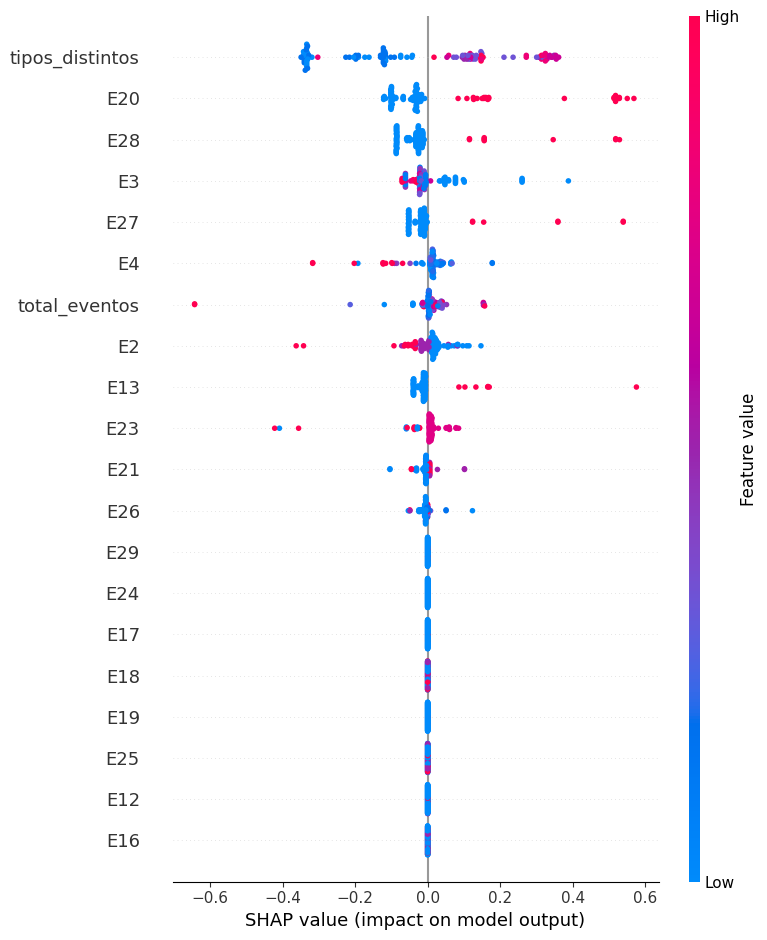

In [ ]:
import shap
import matplotlib.pyplot as plt

final = modelos_finales["Árbol de decisión mejorado"]
nombres = final.named_steps["feat"].get_feature_names_out()
nombres = list(nombres[final.named_steps["var"].get_support()])
X_te_t = final[:-1].transform(Xte)

explicador = shap.TreeExplainer(final.named_steps["clf"])
sv = explicador.shap_values(X_te_t)
if isinstance(sv, list):
    sv = sv[1]
elif sv.ndim == 3:
    sv = sv[:, :, 1]

shap.summary_plot(sv, X_te_t, feature_names=nombres, show=False)
plt.savefig("shap_beeswarm.png", dpi=150, bbox_inches="tight")
plt.show()

In [ ]:
pd.set_option("display.max_colwidth", None)

plant_raw = pd.read_csv(f"{DATA_DIR}/HDFS.log_templates.csv")
plant = plant_raw.set_index(plant_raw.columns[0])[plant_raw.columns[1]]

imp = pd.DataFrame({"variable": nombres, "shap_medio_abs": np.abs(sv).mean(axis=0)})
imp["plantilla"] = imp["variable"].map(plant)
print("Variables sin plantilla:", imp["plantilla"].isna().sum())
imp.sort_values("shap_medio_abs", ascending=False).head(8).round(3)

Variables sin plantilla: 2


,variable,shap_medio_abs,plantilla
29,tipos_distintos,0.213,NaN
19,E20,0.122,[*]Unexpected error trying to delete block[*]BlockInfo not found in volumeMap[*]
26,E28,0.061,[*]BLOCK* NameSystem[*]addStoredBlock: addStoredBlock request received for[*]on[*]size[*]But it does not belong to any file[*]
2,E3,0.044,[*]Served block[*]to[*]
25,E27,0.040,[*]BLOCK* NameSystem[*]addStoredBlock: Redundant addStoredBlock request received for[*]on[*]size[*]
3,E4,0.036,[*]Got exception while serving[*]to[*]
28,total_eventos,0.035,NaN
1,E2,0.033,[*]Verification succeeded for[*]


La variable más importante es tipos_distintos, seguida de E20, E28, E3, E27, E4 y E2. E20, E28 y E27 empujan hacia anomalía; E3 y E2 hacia normal. Ninguna variable delata una fuga: Label y Type no están entre las entradas, y tipos_distintos se calcula solo con los conteos del bloque. SHAP describe lo que hace el modelo, no la causa real de las fallas.

## 9. Análisis de resultados

Sobreajuste: F1 de 0.965 en entrenamiento y 0.949 en prueba. La brecha de 0.016 indica sobreajuste moderado, sin subajuste.

In [ ]:
from sklearn.metrics import f1_score

f1_train = f1_score(yfin, final.predict(Xfin))
f1_test = f1_score(yte, final.predict(Xte))
print(f"F1 entrenamiento: {f1_train:.3f} | F1 test: {f1_test:.3f} | brecha: {f1_train - f1_test:.3f}")

F1 entrenamiento: 0.965 | F1 test: 0.949 | brecha: 0.016


Curva de aprendizaje: la validación cruzada sigue subiendo al final y es ruidosa, por lo que más datos probablemente ayudarían.

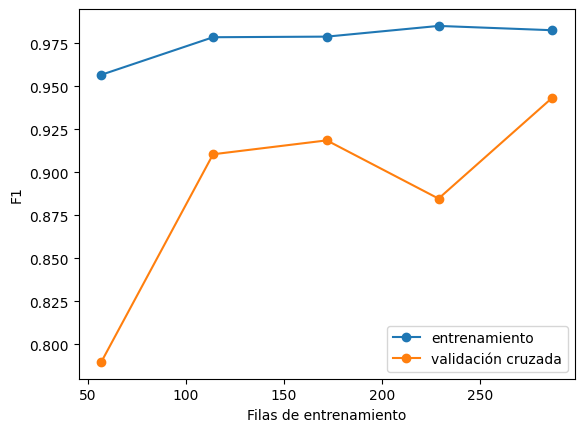

In [ ]:
from sklearn.model_selection import learning_curve

cvl = StratifiedGroupKFold(n_splits=5, shuffle=True, random_state=SEED)
tam, sc_tr, sc_va = learning_curve(
    clone(busqueda.best_estimator_), Xtr, ytr, groups=ktr, cv=cvl,
    scoring="f1", train_sizes=np.linspace(0.2, 1.0, 5), n_jobs=2)

plt.plot(tam, sc_tr.mean(axis=1), "o-", label="entrenamiento")
plt.plot(tam, sc_va.mean(axis=1), "o-", label="validación cruzada")
plt.xlabel("Filas de entrenamiento")
plt.ylabel("F1")
plt.legend()
plt.savefig("curva_aprendizaje.png", dpi=150, bbox_inches="tight")
plt.show()

Errores en prueba: 8 de 120 bloques, 4 falsas alarmas más 1 falsa alarma contradictoria, y 2 falsos negativos más 1 contradictorio. Los 2 vectores contradictorios no se pueden acertar en ambas copias. En los 6 errores restantes no se identificó un patrón claro; el falso negativo 109 destaca por un conteo muy alto de E3 (203), que en SHAP empuja hacia normal. Es una hipótesis no verificada.

In [ ]:
pred = final.predict(Xte)
fallo = pred != yte

contra = set(etiquetas_por_vector[etiquetas_por_vector > 1].index)

err = Xte[fallo].copy()
err["tipo"] = np.where(yte[fallo] == 1, "FN (anomalía no detectada)", "FP (falsa alarma)")
err["vector_contradictorio"] = [k in contra for k in kte[fallo]]
err["eventos"] = err[EVENT_COLS].apply(
    lambda f: ", ".join(f"{c}:{int(v)}" for c, v in f.items() if v > 0), axis=1)
err[["tipo", "vector_contradictorio", "eventos"]]

,tipo,vector_contradictorio,eventos
9,FN (anomalía no detectada),True,"E2:1, E3:1, E4:15, E5:3, E9:3, E11:3, E21:3, E22:1, E23:3, E26:4, E28:1"
20,FN (anomalía no detectada),False,"E2:1, E3:1, E5:4, E6:1, E9:3, E11:3, E16:1, E18:1, E20:1, E21:4, E22:1, E23:3, E25:1, E26:4"
57,FP (falsa alarma),False,"E3:3, E5:9, E6:6, E9:3, E11:3, E16:3, E18:3, E21:9, E22:1, E23:9, E25:3, E26:9"
61,FP (falsa alarma),False,"E3:1, E4:2, E5:4, E6:1, E9:3, E11:3, E16:1, E18:1, E21:4, E22:1, E23:4, E25:1, E26:5"
62,FP (falsa alarma),True,"E2:1, E3:1, E4:2, E5:4, E6:1, E9:3, E11:3, E16:1, E18:1, E21:4, E22:1, E23:3, E25:1, E26:4"
91,FP (falsa alarma),False,"E5:5, E6:2, E9:3, E11:3, E16:1, E18:1, E20:2, E21:5, E22:1, E23:5, E25:1, E26:5"
94,FP (falsa alarma),False,"E2:1, E5:4, E6:1, E9:3, E11:3, E16:1, E18:1, E21:1, E22:1, E25:1, E26:5"
109,FN (anomalía no detectada),False,"E3:203, E5:12, E6:8, E7:1, E9:3, E11:3, E16:5, E18:5, E21:11, E22:1, E23:10, E25:5, E26:11"


## 10. Guardado de resultados

In [ ]:
import joblib, json, os

for carpeta in ["models", "results", "figures"]:
    os.makedirs(carpeta, exist_ok=True)

joblib.dump(final, "models/arbol_mejorado_hdfs.joblib")
json.dump(busqueda.best_params_, open("models/mejores_parametros.json", "w"), indent=1, default=str)

pd.DataFrame(resultados_val).T.round(4).to_csv("results/validacion.csv")
pd.DataFrame(resultados_test).T.round(4).to_csv("results/test.csv")
pd.DataFrame(busqueda.cv_results_).drop(columns=["params"]).to_csv("results/cv_results.csv", index=False)

!mv -f shap_beeswarm.png curva_aprendizaje.png figures/ 2>/dev/null

In [ ]:
config = {
    "semilla": SEED,
    "particion": "60/20/20 por vector único, estratificada",
    "validacion_cruzada": "StratifiedGroupKFold(5), agrupada por vector",
    "metrica_busqueda": "f1",
    "regla_parsimonia": "configuraciones a menos de 0.005 de F1 del mejor; se elige la más simple",
    "rejilla": REJILLA,
    "mejores_parametros": busqueda.best_params_,
    "baseline_literatura_f1": BASELINE_LITERATURA_F1,
}
json.dump(config, open("results/config.json", "w"), indent=1, default=str)

In [ ]:
!zip -rq resultados_etapa2.zip models results figures
from google.colab import files
files.download("resultados_etapa2.zip")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

## 11. Conclusiones
El protocolo evita la fuga: preprocesamiento dentro del pipeline, partición por vector único y prueba usada una sola vez. Todos los modelos reales superan con claridad a los baselines triviales. El árbol mejorado queda a la par de la literatura y de la regresión logística, sin superarlos con certeza. Las variables derivadas y el ajuste no mejoraron claramente al árbol por defecto en validación. SHAP muestra que dominan la diversidad de eventos del bloque y mensajes de error del sistema de archivos.

## 12. Limitaciones
La prueba tiene solo 120 filas y los intervalos son amplios. Tras deduplicar, cerca del 65 por ciento de las filas son anomalías, frente al 2.93 por ciento del log original, por lo que las métricas no se extrapolan a un uso real. Los vectores con etiquetas contradictorias imponen un error mínimo. Se usó una sola partición, sin repetir con otras semillas. La comparación con la literatura es aproximada por las diferencias de protocolo.

## 13. Declaración de uso de IA
Se usó Claude Sonnet 5.5 Medium (Anthropic) como asistente para planificar la estructura del cuaderno, explicar conceptos y revisar el código. El código fue ejecutado en Google Colab por los integrantes y los resultados reportados son los que produjo el cuaderno.